# Venn Diagram

**Family:** Part-to-whole &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Part-to-whole:* Show how a single entity breaks down into its components.

## Design purpose

Overlapping circles that show how two or three sets share members. Each region is labeled with its count, so readers see the size of every combination, including what is unique and what is shared.

## When to use

- Show overlap between 2–3 groups (customers holding products A, B, C)
- Compare gene lists, customer segments, or feature sets

## Avoid when

- There are more than 3 sets (use an UpSet plot)
- Exact area proportionality is expected (it is only approximate for 3 sets)

## Alternatives

- UpSet plot
- Euler diagram
- Grouped bar of intersections

## Example

Product holdings of 1,000 retail-bank customers: checking account, credit card, brokerage account.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from matplotlib_venn import venn3

### Data

In [2]:
# region sizes in the order: (100, 010, 110, 001, 101, 011, 111)
subsets = {"Checking only": 210, "Card only": 90, "Checking∩Card": 70, "Brokerage only": 160,
           "Checking∩Brokerage": 95, "Card∩Brokerage": 55, "All three": 40}
subsets

{'Checking only': 210,
 'Card only': 90,
 'Checking∩Card': 70,
 'Brokerage only': 160,
 'Checking∩Brokerage': 95,
 'Card∩Brokerage': 55,
 'All three': 40}

### Plot

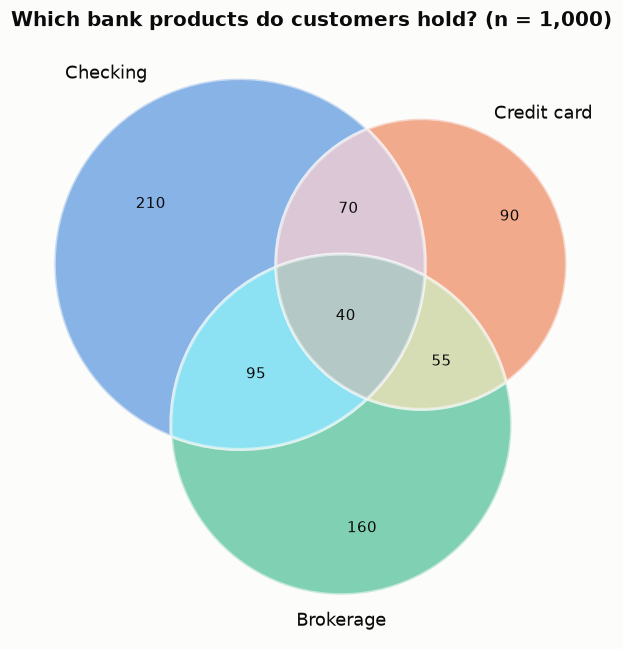

In [3]:
fig, ax = plt.subplots(figsize=(7, 6))
v = venn3(subsets=tuple(subsets.values()),
          set_labels=("Checking", "Credit card", "Brokerage"),
          set_colors=PALETTE[:3], alpha=0.55, ax=ax)
for patch in v.patches:
    if patch is not None:
        patch.set_edgecolor("#fcfcfb")
        patch.set_linewidth(2)
for t in v.subset_labels:
    if t is not None:
        t.set_fontsize(10)
ax.set_title("Which bank products do customers hold? (n = 1,000)")
fig.tight_layout()
plt.show()

## How to read it

Each region's number counts the customers with exactly that combination of products. The center shows the 40 customers who hold all three, the bank's most cross-sold segment.

---
Standalone script: [`venn_diagram.py`](venn_diagram.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)